NameError: name 'df_harian' is not defined

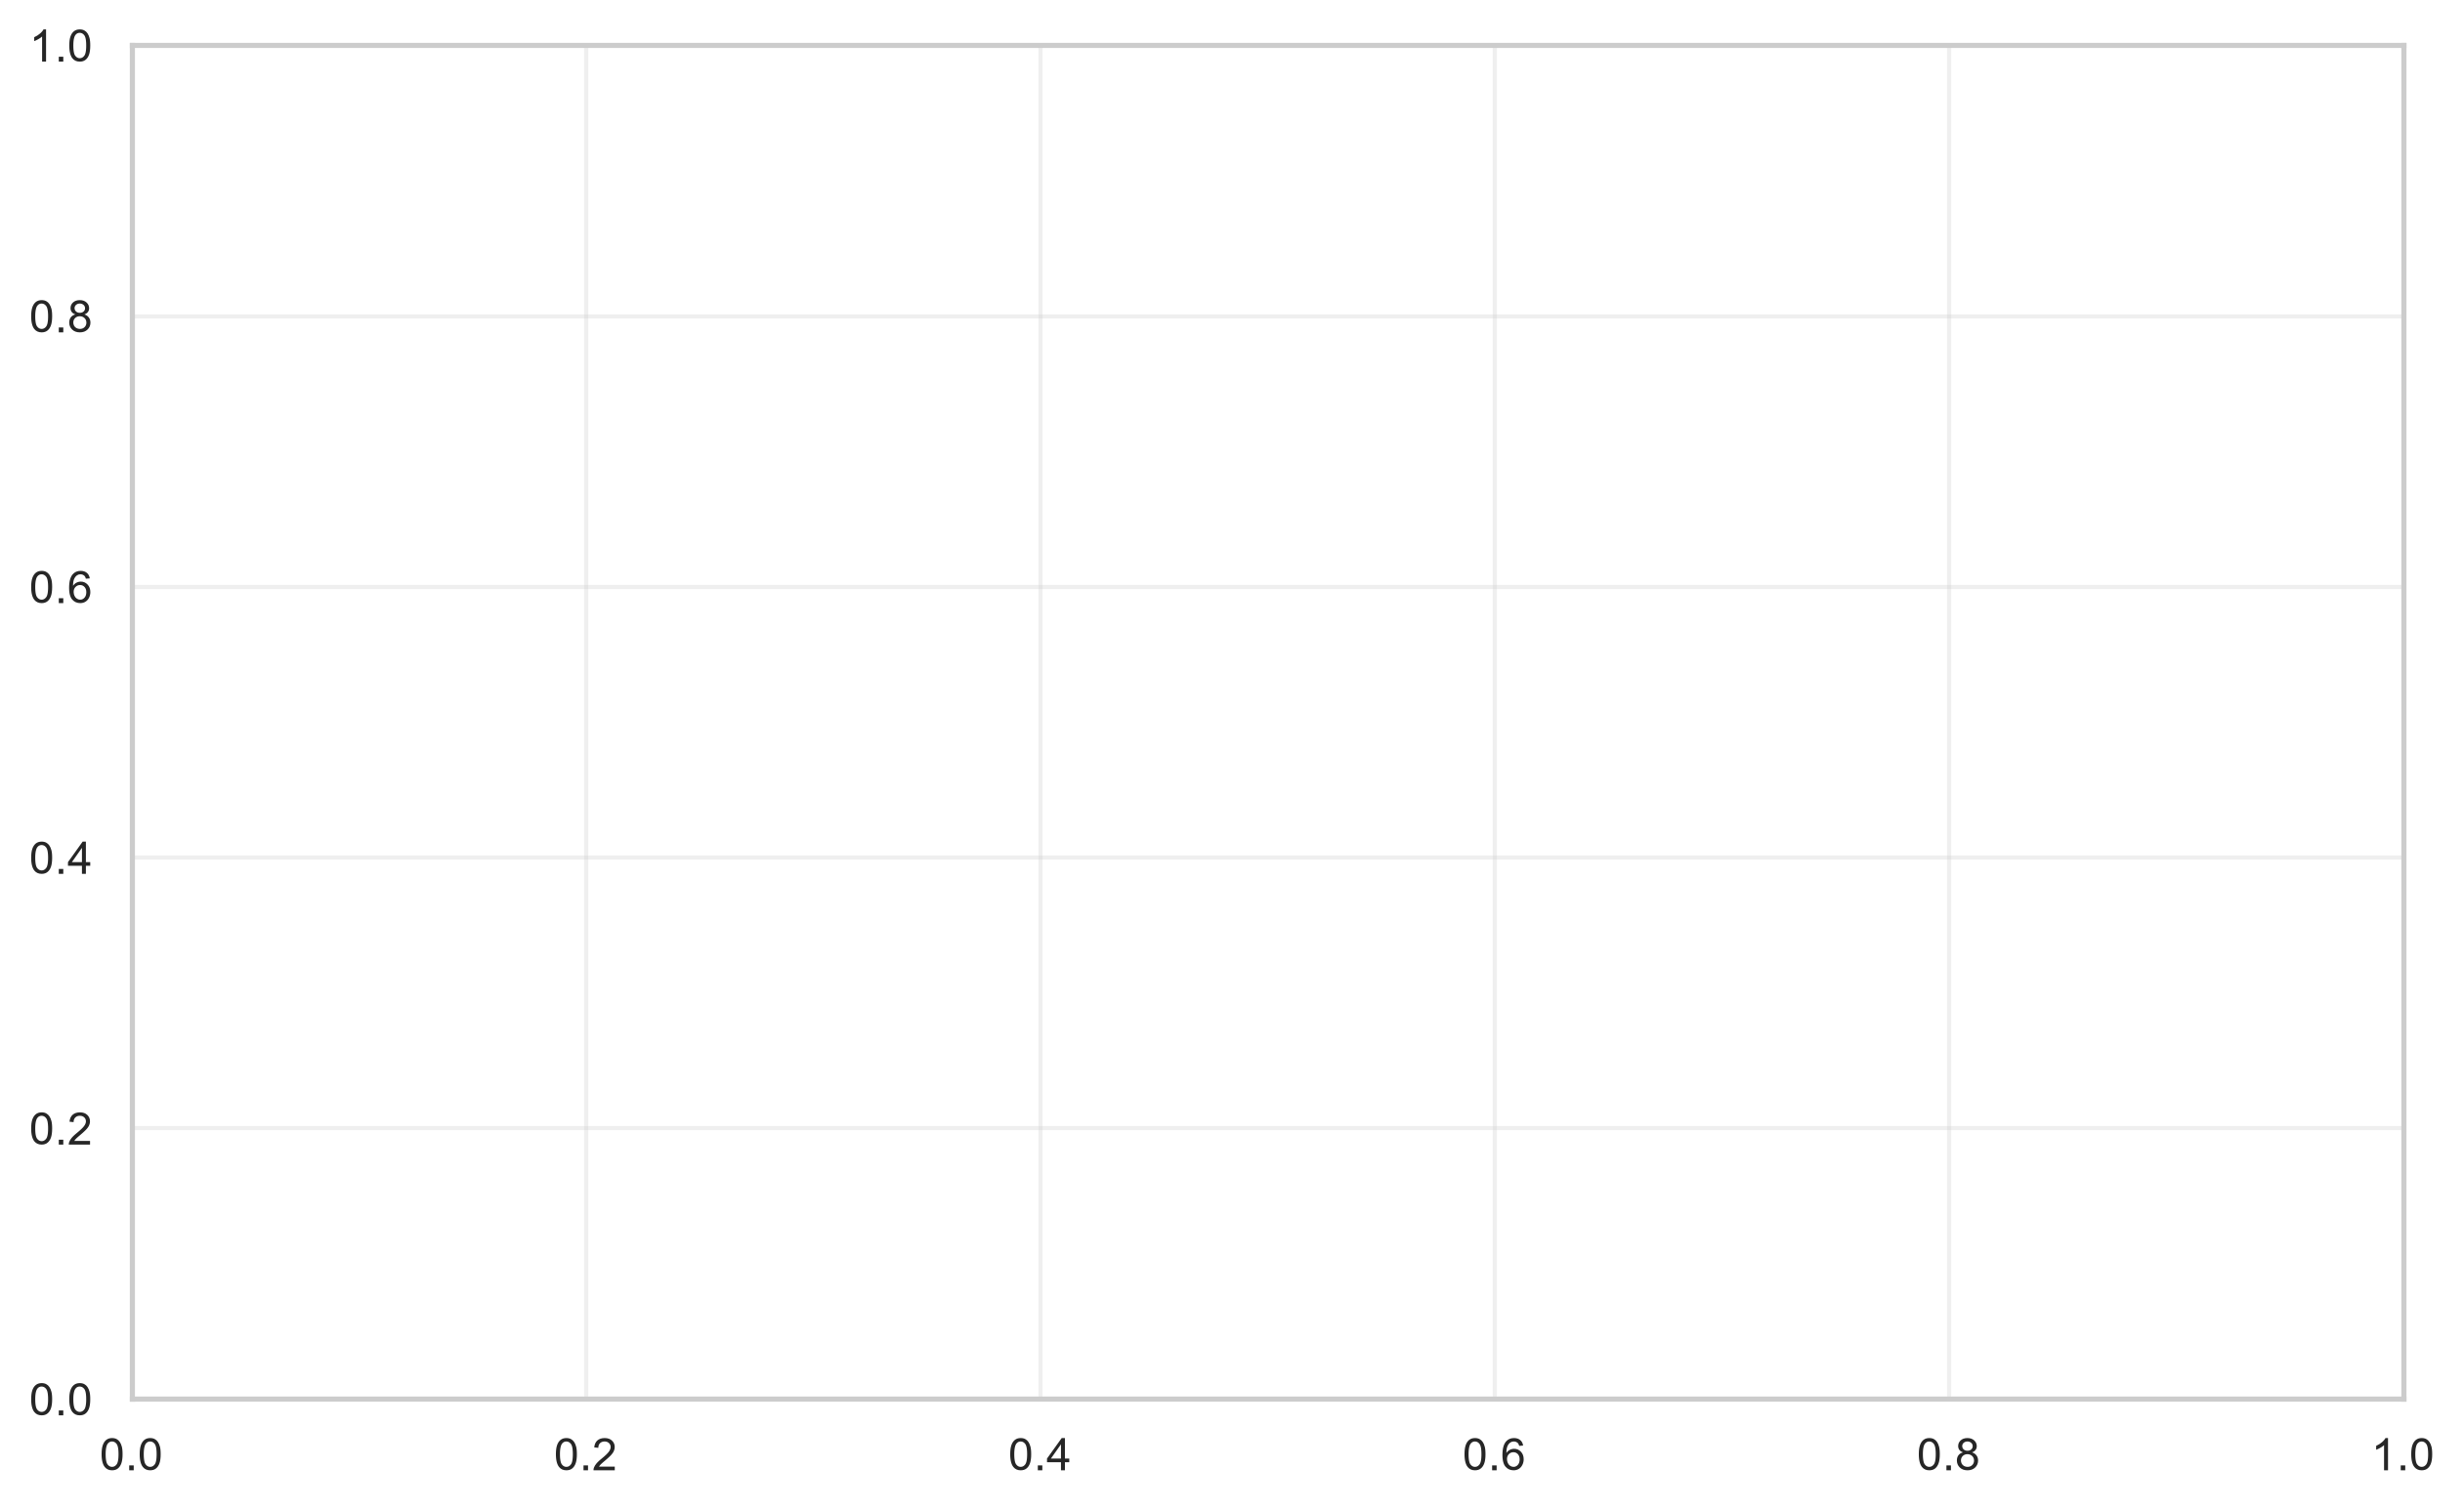

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# =========================================================
# 1. KONFIGURASI GLOBAL UNTUK STANDAR JURNAL (WAJIB)
# =========================================================
plt.rcParams.update({
    'figure.figsize': (10, 6),    # Proporsi lebih seimbang (tidak terlalu pipih)
    'figure.dpi': 300,            # Resolusi 300 DPI agar gambar tajam dan tidak pecah saat dicetak/zoom
    'font.size': 11,              # Ukuran teks dasar
    'axes.titlesize': 12,         # Ukuran judul grafik (sedikit lebih besar)
    'axes.titleweight': 'bold',   # Judul ditebalkan
    'axes.labelsize': 11,         # Ukuran label X dan Y
    'xtick.labelsize': 10,        # Angka di sumbu X
    'ytick.labelsize': 10,        # Angka di sumbu Y
    'legend.fontsize': 10,
    'axes.grid': True,            # Nyalakan gridline untuk memudahkan pembacaan
    'grid.alpha': 0.3,            # Transparansi grid agar tidak menutupi data
    'grid.linestyle': '--'        # Gaya garis grid putus-putus
})

# Gunakan style seaborn agar lebih elegan (opsional tapi disarankan)
sns.set_theme(style="whitegrid", rc=plt.rcParams)

# =========================================================
# 2. GRAFIK 1: POLA KONSUMSI HARIAN (BEBAN LISTRIK)
# =========================================================
fig1, ax1 = plt.subplots()

# TODO: Ganti 'jam' dan 'beban' sesuai dengan nama kolom di datamu
sns.lineplot(x='jam', y='beban', data=df_harian, ax=ax1, color='#1f77b4', linewidth=2)

# Mencari nilai puncak untuk anotasi (panah)
# Asumsi: x_puncak adalah 19 (Jam 19:00), ganti y_puncak dengan nilai aslinya
x_puncak = 19
y_puncak = df_harian['beban'].max() # Mengambil nilai tertinggi dari data

# Menambahkan panah penunjuk (Anotasi)
ax1.annotate('Puncak Beban\n(19:00)', 
             xy=(x_puncak, y_puncak), 
             xytext=(x_puncak - 4, y_puncak * 1.02), # Geser teks sedikit ke kiri dan atas
             arrowprops=dict(facecolor='red', shrink=0.05, width=1.5, headwidth=8),
             fontsize=10, color='darkred', fontweight='bold')

ax1.set_title('Pola Konsumsi Beban Listrik Harian', pad=15)
ax1.set_xlabel('Waktu (Jam)')
ax1.set_ylabel('Beban Listrik (kW)')

# Menyempurnakan margin agar tidak terpotong saat disimpan
plt.tight_layout()

# Menyimpan gambar siap pakai untuk Jurnal
plt.savefig('grafik_pola_harian_jurnal.png', dpi=300, bbox_inches='tight')
plt.show()

# =========================================================
# 3. GRAFIK 2: PENGARUH SUHU PADA BEBAN LISTRIK
# =========================================================
fig2, ax2 = plt.subplots()

# TODO: Ganti nama kolom sesuai dengan datamu
sns.scatterplot(x='apparent_temperature', y='beban', data=df_suhu, ax=ax2, 
                color='#ff7f0e', alpha=0.6, s=50) # alpha agar titik yang bertumpuk terlihat, s = ukuran titik

# Menambahkan garis tren (Regresi Plot) untuk menunjukkan korelasi (Sangat disukai reviewer jurnal)
sns.regplot(x='apparent_temperature', y='beban', data=df_suhu, ax=ax2, 
            scatter=False, color='red', line_kws={"linewidth": 2, "linestyle": "--"})

ax2.set_title('Hubungan Suhu Lingkungan (Apparent Temperature) terhadap Beban Listrik', pad=15)
ax2.set_xlabel('Apparent Temperature (°C)')
ax2.set_ylabel('Konsumsi Energi Rata-rata')

# Menyempurnakan margin
plt.tight_layout()

# Menyimpan gambar siap pakai untuk Jurnal
plt.savefig('grafik_pengaruh_suhu_jurnal.png', dpi=300, bbox_inches='tight')
plt.show()